# Depois da reunião com a Loft: o que fizemos e por quê

**Beatriz Babinski** · Projeto em Ciência de Dados V · IBMEC

O notebook `02_poc_clusterizacao.ipynb` mostra a POC inteira. **Este aqui conta só a segunda rodada**: o que a Loft
pediu e mandou depois da reunião, o que a gente fez com cada coisa e por que fez assim.

| Passo | Pergunta | Por que importa |
| --- | --- | --- |
| 0 | O que a Loft pediu e mandou? | é o ponto de partida desta rodada |
| 1 | A base de anúncios está completa? | dado incompleto usado sem olhar engana a validação |
| 2 | Como fica o mercado com o CNAE da Loft? | a gente deixava de fora o CNAE de aluguel, o mais ligado à fiança |
| 3 | O que mudou ao rodar o modelo de novo? | o vencedor automático mudou, e precisou de critério |
| 4 | Por que ficamos com o conjunto D? | as regras de escolha ficaram explícitas |
| 5 | As praças mudaram muito? | a Loft já viu a versão anterior |
| 6 | As praças se repetem em cidades novas? | validação metade treino / metade teste, pedida pelo professor |
| 7 | As praças batem com os anúncios reais? | primeira prova com dado da própria Loft |
| 8 | A imobiliária também vende? | pergunta do professor sobre a fiança |
| 9 | O que falta? | o que só dá para fazer com o dado de mídia da Loft |

**Como rodar:** antes, `make poc` (gera as tabelas). Os passos 1 e 7 só aparecem completos na máquina que tem a base
de anúncios da Loft em `data/raw/`. Essa base **não vai para o GitHub**, então aqui só aparecem estatísticas e índices,
nunca os volumes de anúncio.

In [1]:
# ============================================================
# PREPARAÇÃO: liga as ferramentas e acha as pastas do projeto
# ============================================================
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import adjusted_rand_score

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))      # para importar o código do projeto
from ibmecPCDV20261_victor_lucas_beatriz_ravi.poc_clusters import anuncios, config

TABELAS = RAIZ / 'reports' / 'tables'
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)

def tabela(nome):
    return pd.read_csv(TABELAS / f'{nome}.csv')

# Base municipal que o pipeline montou (687 municípios), já com o tipo de praça novo.
base = pd.read_csv(RAIZ / 'data' / 'processed' / 'base_municipios.csv', dtype={'id_municipio': str})
print(len(base), 'municípios')

687 municípios


## 0. O que a Loft pediu e mandou

Na reunião, a Loft pediu três coisas que mexem nesta POC:

1. **Usar o mesmo filtro de CNAE que eles usam** para achar imobiliária potencial. Eles mandaram a regra:
   empresa ativa (`situacao_cadastral = 2`) e CNAE principal em **6821801** (compra e venda), **6821802** (aluguel)
   ou **6822600** (gestão). O CNAE secundário eles **não usam para filtrar**, só para entender o perfil.
2. **Cruzar as praças com a base de anúncios dos portais**, para ver se as praças "maduras" têm mesmo mais mercado.
3. Mais adiante, cruzar com investimento, MQL e cadastro (isso ainda não chegou, é o passo 9).

E o professor pediu: **validação metade treino / metade teste**, e perguntou se, para a fiança, importa a imobiliária
também conseguir vender o imóvel.

## 1. A base de anúncios está completa?

> **O QUE É:** a base de anúncios dos portais tem uma linha por mês, cidade, bairro e tipo (venda ou aluguel). Antes de usar, olho mês a mês quanta coisa ela tem.
>
> **POR QUÊ:** se a coleta mudou no meio do caminho, comparar meses diferentes mistura mudança de coleta com mudança de mercado. Preciso achar um período estável.
>
> **O QUE OLHAR:** o gráfico mostra o volume de cada mês **como índice** (média de abr a ago/2026 = 100), para não expor o volume da Loft. Repare no salto em nov/2024, no buraco de fev e mar/2026 e no último mês pela metade.

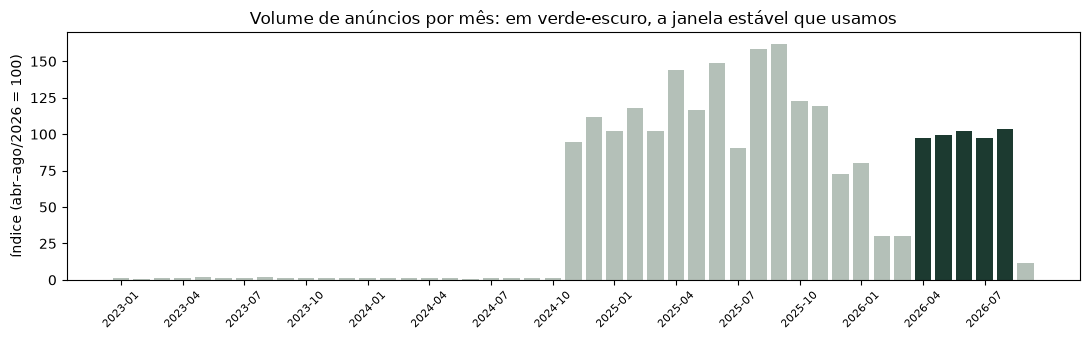

cidades diferentes na base: 1025


In [2]:
# Lê só as colunas necessárias da base bruta da Loft (fica em data/raw, fora do GitHub).
arquivos = sorted(config.DIR_RAW.glob(anuncios.PADRAO_ARQUIVO))
if arquivos:
    bruto = pd.read_csv(arquivos[-1], usecols=['snapshot_month', 'normalized_state_seed',
                                                'normalized_city_seed', 'operation_type', 'n_listings'])
    por_mes = bruto.groupby('snapshot_month')['n_listings'].sum()
    janela = por_mes.loc[anuncios.INICIO_JANELA:anuncios.FIM_JANELA].mean()
    indice = (por_mes / janela * 100).round(1)          # índice: janela estável = 100

    fig, ax = plt.subplots(figsize=(11, 3.5))
    cores = ['#1C3A30' if anuncios.INICIO_JANELA <= m <= anuncios.FIM_JANELA else '#B4C0B8' for m in indice.index]
    ax.bar(range(len(indice)), indice.values, color=cores)
    ax.set_xticks(range(0, len(indice), 3), [m[:7] for m in indice.index[::3]], rotation=45, fontsize=8)
    ax.set_ylabel('índice (abr–ago/2026 = 100)')
    ax.set_title('Volume de anúncios por mês: em verde-escuro, a janela estável que usamos')
    plt.tight_layout(); plt.show()
    print('cidades diferentes na base:', bruto.groupby(['normalized_state_seed', 'normalized_city_seed']).ngroups)
else:
    display(Markdown('_Base de anúncios da Loft não está nesta máquina._'))

**Conclusão do passo 1:** a base **não é completa**. Até out/2024 a coleta era bem menor (o volume salta umas 30 vezes
em nov/2024), fev e mar/2026 têm um buraco e o último mês está pela metade. Por isso usamos **só abr a ago/2026**,
pela mediana mensal de cada cidade. A mediana não deixa um mês esquisito puxar o número.

## 2. O mercado com o CNAE da Loft

> **O QUE É:** troquei o filtro de imobiliária pelo da Loft. A variável de mercado passou a ser **imobiliárias potenciais por 10 mil habitantes** (os 3 CNAEs juntos). Criei também o **% de imobiliárias de aluguel ou gestão** e, só para descrever, o **% que tem aluguel no CNAE principal ou secundário**.
>
> **POR QUÊ:** antes a gente usava só 6821801 e 6822600 e deixava de fora o **6821802 (aluguel)**, que é justamente o mais ligado à fiança. E medir o mercado do mesmo jeito que a Loft deixa o resultado comparável com o que eles já usam.
>
> **O QUE OLHAR:** a coluna `parcela_pct`: quanto cada CNAE pesa no universo. E a última linha: quantas imobiliárias trabalham com aluguel.

In [3]:
# Soma dos 687 municípios. O código que faz a consulta está em coleta/cnpj.py.
quebra = pd.DataFrame({
    'CNAE principal': ['6821801 · compra e venda', '6821802 · aluguel', '6822600 · gestão'],
    'empresas_ativas': [base['imobiliarias'].sum(), base['corretoras_aluguel'].sum(), base['administradoras'].sum()],
})
quebra['parcela_pct'] = (quebra['empresas_ativas'] / quebra['empresas_ativas'].sum() * 100).round(1)
display(quebra)

faz_aluguel = base['setor_faz_aluguel'].sum() / base['setor_total'].sum() * 100
print(f'Universo Loft nos 687 municípios: {int(base["setor_total"].sum()):,} imobiliárias'.replace(',', '.'))
print(f'Com aluguel no CNAE principal ou secundário: {faz_aluguel:.0f}%')

,CNAE principal,empresas_ativas,parcela_pct
0,6821801 · compra e venda,90111.0,61.1
1,6821802 · aluguel,16140.0,10.9
2,6822600 · gestão,41205.0,27.9


Universo Loft nos 687 municípios: 147.456 imobiliárias
Com aluguel no CNAE principal ou secundário: 57%


**Achado:** em todo o Brasil, **65% das imobiliárias de compra e venda também têm aluguel como CNAE secundário**
(consulta direta ao CNPJ, fora deste notebook). Ou seja, o CNAE principal sozinho subestima quem trabalha com locação.
No universo inteiro da Loft (os três CNAEs) a parcela com aluguel é de 57%, como mostra a célula acima. Por isso o
secundário vale como **perfil** da praça, igual a Loft usa.

## 3. Rodando o modelo de novo: o vencedor automático mudou

> **O QUE É:** rodei de novo os 5 conjuntos de variáveis (A a E), com 3 algoritmos e k de 2 a 10, agora com o CNAE da Loft.
>
> **POR QUÊ:** mudar a medida de mercado muda a distância entre as cidades, então os grupos podem mudar.
>
> **O QUE OLHAR:** a coluna `maior_cluster_pct`. O conjunto E, que agora separa bem, junta **quase metade das cidades numa praça só**.

In [4]:
# Cada conjunto no seu k do 'cotovelo' (o ponto em que mais grupos param de compensar), só KMeans.
var = tabela('08_varredura_k')
cotovelo = {'A': 5, 'B': 4, 'C': 5, 'D': 5, 'E': 4}
linhas = var[(var['modelo'] == 'kmeans') & var.apply(lambda r: r['k'] == cotovelo[r['grupo']], axis=1)]
linhas[['grupo', 'nome_grupo', 'k', 'silhueta', 'menor_cluster', 'maior_cluster_pct']].round(3)

,grupo,nome_grupo,k,silhueta,menor_cluster,maior_cluster_pct
3,A,Mercado imobiliário,5,0.250,38,38.9
29,B,Capacidade de pagamento,4,0.325,79,34.2
57,C,Mercado + renda,5,0.303,62,33.2
84,D,Mercado + renda + marketing,5,0.266,84,31.1
110,E,Mercado + risco + concorrência + demanda,4,0.292,77,48.8


**Leitura:** pela regra antiga (maior silhueta entre os conjuntos com mercado e renda), o vencedor seria o **E com 4
praças**. Só que:

- uma praça só ficaria com **49% das cidades e 70% da população**. Ela vira "o resto do Brasil" e não orienta verba;
- o E não tem variável de renda nem de alcance digital, então os nomes saíram "intermediária 1, 2, 3", sem leitura de
  negócio.

Silhueta alta não basta: o agrupamento precisa servir para a decisão.

## 4. Por que ficamos com o conjunto D

> **O QUE É:** deixei o critério de escolha explícito em três regras de negócio e coloquei no código (`pipeline.py`).
>
> **POR QUÊ:** a escolha anterior dependia de um desempate apertado. Com regra escrita, qualquer pessoa consegue refazer a escolha e discordar dela por um motivo claro.
>
> **O QUE OLHAR:** na tabela, o D (escolhido) contra o concorrente mais forte que ficou de fora (C).

As três regras:

1. **O conjunto precisa ter mercado, capacidade de pagamento e alcance digital.** A pergunta da Loft é *onde pôr mídia
   PAGA*: sem saber se a mídia alcança o público, não dá para saber se o real investido chega a alguém.
2. **Nenhuma praça pode ter mais de 40% das cidades.** Senão ela não separa nada.
3. **Toda praça precisa de pelo menos 20 cidades.** Senão o resultado vale para poucas cidades e não se sustenta.

In [5]:
# Tabela 09b: o escolhido e o concorrente mais forte que não passou nas regras.
display(tabela('09b_escolha_do_modelo')[['grupo', 'nome_grupo', 'k', 'silhueta', 'estabilidade_bootstrap', 'escolhido']].round(3))

# Tabela 14b: a diferença de silhueta entre D e C é real ou é ruído? 200 reamostragens.
tabela('14b_diferenca_de_silhueta')[['configuracao_a', 'configuracao_b', 'diferenca_media',
                                     'intervalo_95_inferior', 'intervalo_95_superior', 'diferenca_significativa']]

,grupo,nome_grupo,k,silhueta,estabilidade_bootstrap,escolhido
0,D,Mercado + renda + marketing,5,0.266,0.794,True
1,C,Mercado + renda,5,0.303,0.775,False


,configuracao_a,configuracao_b,diferenca_media,intervalo_95_inferior,intervalo_95_superior,diferenca_significativa
0,D,C,-0.027,-0.0423,-0.0114,True


**Honestidade:** o C separa um pouco melhor que o D, e a diferença é real (o intervalo não cruza o zero). Mas é uma
diferença pequena (cerca de 0,03) perto da vantagem do modelo sobre a geografia (cerca de 0,26). E o D é um pouco mais
estável. **Ficamos com o D porque é o único com as três dimensões que a decisão de mídia exige**, não porque ganha
em tudo.

In [6]:
# O teste que importa (baseline): o D ganha de região, de porte e de sorteio?
tabela('11_baselines_modelo_final')

,agrupamento,n_grupos,silhueta,rand_ajustado_vs_cluster
0,Clusters da POC,5,0.2664,1.0000
1,Baseline: 5 regiões do IBGE,5,0.0049,0.1878
2,Baseline: faixas de porte populacional,5,-0.1083,0.0347
3,Baseline: sorteio aleatório (média de 30),5,-0.0339,-0.0002


## 5. As praças mudaram muito em relação ao que apresentamos?

> **O QUE É:** comparo, cidade a cidade, a praça da versão apresentada com a praça da versão nova.
>
> **POR QUÊ:** a Loft já viu a versão anterior. Preciso saber se a história continua de pé ou se mudou tudo.
>
> **O QUE OLHAR:** o Rand ajustado (1 = idêntico, 0 = nada a ver) e a tabela cruzada: na diagonal estão as cidades que ficaram na mesma praça.

In [7]:
antes = tabela('26_praca_versao_apresentada')[['id_municipio', 'tipo_de_praca_apresentado']]
antes['id_municipio'] = antes['id_municipio'].astype(str)
comparacao = base[['id_municipio', 'municipio', 'sigla_uf', 'populacao', 'nome_cluster']].merge(antes, on='id_municipio')

ari = adjusted_rand_score(comparacao['tipo_de_praca_apresentado'], comparacao['nome_cluster'])
mesma = (comparacao['tipo_de_praca_apresentado'] == comparacao['nome_cluster']).mean() * 100
print(f'Rand ajustado entre a versão apresentada e a nova: {ari:.2f}')
print(f'Cidades que ficaram na mesma praça: {mesma:.0f}%')

pd.crosstab(comparacao['tipo_de_praca_apresentado'], comparacao['nome_cluster'],
            rownames=['ANTES (apresentado)'], colnames=['DEPOIS (CNAE Loft)'])

Rand ajustado entre a versão apresentada e a nova: 0.72
Cidades que ficaram na mesma praça: 87%


DEPOIS (CNAE Loft),Praça em formação,Praça intermediária conectada,Praça madura de locação,Praça popular de grande porte,Praça sem mercado formal
ANTES (apresentado),,,,,
Praça em formação,70,1,0,2,0
Praça intermediária conectada,2,198,8,8,3
Praça madura de locação,0,14,111,6,0
Praça popular de grande porte,20,1,0,141,5
Praça sem mercado formal,21,0,0,0,76


In [8]:
# As maiores cidades que trocaram de praça: é aqui que o CNAE de aluguel fez diferença.
trocaram = comparacao[comparacao['tipo_de_praca_apresentado'] != comparacao['nome_cluster']]
trocaram.nlargest(10, 'populacao')[['municipio', 'sigla_uf', 'populacao', 'tipo_de_praca_apresentado', 'nome_cluster']]

,municipio,sigla_uf,populacao,tipo_de_praca_apresentado,nome_cluster
116,Fortaleza,CE,2582360,Praça madura de locação,Praça popular de grande porte
248,Salvador,BA,2559945,Praça madura de locação,Praça popular de grande porte
188,Recife,PE,1588983,Praça madura de locação,Praça popular de grande porte
92,São Luís,MA,1090229,Praça madura de locação,Praça popular de grande porte
371,São Gonçalo,RJ,959977,Praça popular de grande porte,Praça em formação
264,Betim,MG,433902,Praça intermediária conectada,Praça popular de grande porte
662,Anápolis,GO,424647,Praça madura de locação,Praça popular de grande porte
408,Carapicuíba,SP,398772,Praça intermediária conectada,Praça popular de grande porte
185,Paulista,PE,367155,Praça popular de grande porte,Praça em formação
550,São José dos Pinhais,PR,353874,Praça madura de locação,Praça intermediária conectada


**Leitura:** os **mesmos 5 tipos de praça** continuam, com os mesmos nomes, e cerca de 87% das cidades ficaram onde
estavam. As trocas que importam são duas:

- **Capitais do Nordeste (Fortaleza, Salvador, Recife, São Luís) saíram da madura para a popular de grande porte.**
  Antes o mercado era medido só por administradoras (gestão), e nisso elas estavam no nível das capitais do Sul e
  Sudeste. Com o universo completo da Loft, elas têm cerca de 7 a 11 imobiliárias por 10 mil habitantes, contra 14 na
  mediana da praça madura, e o CadÚnico delas é bem mais alto (55% a 66% contra 35%). A leitura nova é mais coerente
  com o risco da fiança.
- **A praça em formação cresceu de 73 para 113 cidades.** Ela recebeu cidades que eram popular ou sem mercado formal.
  O custo disso é que o sinal que define essa praça (imobiliárias abertas nos últimos 12 meses) ficou mais fraco: de
  +1,7 para +1,1 desvio acima da média. Vale acompanhar.

## 6. Validação metade treino / metade teste (pedida pelo professor)

> **O QUE É:** sorteio as 687 cidades em duas metades. O modelo aprende **tudo** numa metade: os cortes de valores extremos, o log, a padronização e o centro de cada praça. Depois ele classifica a outra metade, que **nunca viu**. Em paralelo, a outra metade é agrupada sozinha. Comparo as duas classificações. Faço isso 50 vezes, trocando as metades de papel.
>
> **POR QUÊ:** a reamostragem do notebook 02 mede se o resultado muda quando tiro algumas cidades. Aqui a pergunta é mais forte: **o que o modelo aprendeu vale para cidades que ele não conhecia?** É o mais perto de um teste fora da amostra que existe sem gabarito.
>
> **O QUE OLHAR:** o `rand_ajustado_medio`. Perto de 1, as praças se repetem; perto de 0, elas foram sorte da amostra.

In [9]:
# Tabela 13b: 50 sorteios x 2 papéis = 100 comparações. O código está em avaliacao.validacao_metades.
tabela('13b_validacao_metades')

,modelo,k,metodo,n_sorteios,n_comparacoes,rand_ajustado_medio,rand_ajustado_desvio,rand_ajustado_p5,rand_ajustado_p95
0,KMeans,5,"metade treino, metade teste",50,100,0.6593,0.1035,0.493,0.8116


**Leitura:** a concordância média fica em torno de **0,66**. Isso significa que as praças se repetem bem em cidades
novas. Não é 1 porque o Brasil municipal é um **contínuo** (notebook 02, passo 5), então as cidades da fronteira
entre duas praças podem cair de um lado ou do outro. O teste automático do projeto confere que esse método dá perto de
1 em grupos verdadeiros e perto de 0 em ruído puro (`tests/test_poc_clusters.py`).

## 7. Validação externa com os anúncios dos portais

> **O QUE É:** conto, em cada cidade, os anúncios de aluguel por 10 mil habitantes (janela abr–ago/2026) e comparo entre as praças.
>
> **POR QUÊ:** é a primeira prova com um dado que **o modelo nunca viu** e que vem da própria Loft. Se a praça 'madura' é madura, ela tem que ter mais imóvel anunciado. Os anúncios ficaram **fora do modelo** de propósito: se entrassem, o teste compararia o modelo com ele mesmo.
>
> **O QUE OLHAR:** a **ordem** das praças e o p-valor do Kruskal-Wallis (o teste que diz se os grupos têm volumes diferentes de verdade ou por acaso). E a coluna `ganho_do_cluster`, que é a ressalva.

In [10]:
validacao = anuncios.validar(base)     # devolve None se a base da Loft não está nesta máquina
if validacao is None:
    display(Markdown('_Base de anúncios da Loft não está nesta máquina: teste não exibido._'))
else:
    # Só a ORDEM das praças e as estatísticas do teste: os volumes ficam em reports/interno, fora do GitHub.
    ordem = validacao['por_praca'][['nome_cluster', 'municipios', 'com_anuncio_pct']].reset_index(drop=True)
    ordem.index = ordem.index + 1
    ordem.index.name = 'posição em anúncios por habitante'
    display(ordem)
    display(validacao['resumo'])

,nome_cluster,municipios,com_anuncio_pct
posição em anúncios por habitante,,,
1,Praça madura de locação,119,64.7
2,Praça intermediária conectada,214,65.0
3,Praça popular de grande porte,157,59.9
4,Praça em formação,113,29.2
5,Praça sem mercado formal,84,21.4


,janela,municipios_com_anuncio,municipios_total,kruskal_wallis_h,kruskal_wallis_p,r2_regiao_e_porte,r2_com_o_cluster,ganho_do_cluster
0,2026-04 a 2026-08,361,687,145.1,2.326762e-30,0.4997,0.5012,0.0015


In [11]:
# Onde a base de anúncios enxerga: % das nossas cidades com algum anúncio, por região.
if validacao is not None:
    dados = base.copy()
    dados['chave'] = dados['sigla_uf'] + '|' + dados['municipio'].map(anuncios._normalizar)
    cobertas = set(anuncios.carregar().index)
    dados['coberta'] = dados['chave'].isin(cobertas)
    display(dados.groupby('regiao')['coberta'].mean().mul(100).round(0).rename('% com anúncio').to_frame())

,% com anúncio
regiao,
Centro-Oeste,43.0
Nordeste,37.0
Norte,28.0
Sudeste,65.0
Sul,68.0


**Leitura:**

- **A ordem bate:** madura > intermediária conectada > popular de grande porte > em formação > sem mercado formal,
  com p-valor praticamente zero. As praças que o modelo chamou de maduras são as que têm mais imóvel para alugar.
- **Ressalva:** depois de saber a região e o porte da cidade, o cluster acrescenta pouco para explicar o **volume** de
  anúncios (o R² quase não muda). O cluster ordena o mercado, mas o tamanho do mercado anunciado vem sobretudo do porte
  e da região.
- **Limitação:** a base cobre só cerca de metade das cidades e quase nada do Norte e Nordeste. Por isso ela serve como
  prova, não como variável do modelo.

## 8. "A imobiliária também consegue vender?" (pergunta do professor)

> **O QUE É:** mostro, para cada praça, o % de imobiliárias que trabalham com aluguel no CNAE principal ou secundário. É o mesmo jeito que a Loft olha o perfil.
>
> **POR QUÊ:** para a fiança importa se a imobiliária vive de locação ou só de venda. Onde ela faz as duas coisas, o mesmo cliente B2B pode vender fiança e o imóvel.
>
> **O QUE OLHAR:** a diferença entre as praças. Esta variável **não entrou no modelo**, só descreve as praças depois de formadas.

In [12]:
perfil_cnae = (base.groupby('nome_cluster')[['faz_aluguel_pct', 'locacao_pct', 'imobiliarias_loft_10k']]
               .median().round(1).sort_values('imobiliarias_loft_10k', ascending=False))
perfil_cnae.columns = ['% com aluguel no CNAE (mediana)', '% aluguel ou gestão no principal', 'imobiliárias Loft / 10 mil hab.']
perfil_cnae

,% com aluguel no CNAE (mediana),% aluguel ou gestão no principal,imobiliárias Loft / 10 mil hab.
nome_cluster,,,
Praça madura de locação,61.2,34.8,14.1
Praça intermediária conectada,59.1,41.6,6.3
Praça popular de grande porte,57.5,43.8,3.8
Praça em formação,50.0,45.5,1.5
Praça sem mercado formal,31.0,29.5,0.6


**Leitura e dúvida em aberto:** a pergunta do professor pode ter dois sentidos. Ainda vamos confirmar com ele qual era.

- (a) **a imobiliária faz venda e aluguel**: é a tabela acima, com dado público;
- (b) **o dono tem a alternativa de vender em vez de alugar**: dá para medir pela razão entre anúncios de venda e de
  aluguel, com a base da Loft (`reports/interno/26_anuncios_por_praca.csv`, coluna `venda_por_aluguel_mediana`).

## 9. O que falta, e por que depende da Loft

| Próximo passo | Por quê | O que precisa |
| --- | --- | --- |
| Cruzar as praças com investimento, MQL e cadastro | hoje sabemos onde está o mercado, não onde a Loft converte | dado da Loft agregado por data, canal e campanha |
| Custo do próximo MQL por tipo de praça | é a pergunta "onde pôr o próximo R$ 1" em número | o cruzamento acima |
| Simular a realocação | quanto sai de praça de baixa propensão e quantos MQLs a mais entram nas outras | custo por MQL por praça |
| Otimizador de orçamento | dado um orçamento X, como dividir entre canais, campanhas e praças | tudo acima; fiança primeiro, depois outros produtos |

**MQL** = lead qualificado pelo marketing. MQL e cadastro são os sinais de sucesso definidos com a Loft; contrato e
venda vêm depois, como indicadores mais lá na frente do funil.